# Background

- **Author**: 待學生確認（尚未確認本次對話者與實際分工）
- **Created At**: 2026-11-09
- **Research Motivation and Context (why are we interested in the findings?)：** 比較白人比例高（VT、ME、WV）與低（HI、DC、CA）兩個州群，在收入四分位組內白人、亞洲人與黑人的房貸核准率。兩群各合併全部申請紀錄計算，非州核准率的簡單平均。指定資料：[高白人比例組](../data/processed/state_VT-ME-WV_white_high_15_columns.csv)、[低白人比例組](../data/processed/state_HI-DC-CA_white_low_15_columns.csv)、[final 州群個人收入門檻](../data/processed/[final]individual_income_quartiles_by_group.csv)。本 notebook 的讀取驗證與樣本說明同時記錄這三個既有輸入的核對結果；房貸資料上游產生程式與年份未確認，未據檔名推定其年份。
- **Main Findings and Takeaways：** 2026-11-15 已依 final 個人收入門檻從乾淨 kernel 重跑；有效申請 N=581,562，24 組結果已重新讀取核對。以下數字順序為高組／低組：Q1：白人 29.6%／51.1%、亞洲人 36.4%／57.2%、黑人 26.5%／45.2%；Q2：白人 49.9%／47.7%、亞洲人 32.5%／54.2%、黑人 37.5%／38.2%；Q3：白人 69.0%／61.9%、亞洲人 67.9%／51.3%、黑人 63.4%／51.1%；Q4：白人 82.4%／80.8%、亞洲人 85.0%／80.6%、黑人 73.8%／70.0%。圖表與結論均已更新，不能沿用舊家戶收入分組的結論。
- **Future Direction：** 確認房貸資料年份；如需解釋種族差距，後續納入州別、貸款條件與機構差異。本次為描述性比較，不推論因果。

更新日期：2026-11-15。依使用者指示改採 final 個人收入門檻；原家戶收入門檻的圖表與結果表由本次結果取代。個人收入與房貸申請 income 的所得範圍可能不同，本次僅依指定門檻分組，不主張兩者衡量完全一致。


In [1]:
# Load packages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib import font_manager
from IPython.display import Markdown
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Heiti TC', 'Arial Unicode MS', 'Noto Sans CJK TC'] if f in available_fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 11


Matplotlib is building the font cache; this may take a moment.


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents) if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('請從 econ-5166-student-kit 或其子目錄執行。')
INPUTS = {
 'state_VT-ME-WV_white_high_15_columns.csv': 'eb1f7f550eb397ead2f900c142f1521cb4da04a892111b494b9a9d8f2eabbf51',
 'state_HI-DC-CA_white_low_15_columns.csv': '7bc8724fa2db17f65d8a77bb91929be14ae8f063ede116317d24598e49ca1554',
 '[final]individual_income_quartiles_by_group.csv': '9aec1cde45d1b069b71564e3f01228591aa18c302fa9c76b584f90378d4b1651',
}
def read_verified(name):
    path=(PROJECT_ROOT/'data/processed'/name).resolve()
    assert path.is_relative_to((PROJECT_ROOT/'data/processed').resolve())
    if hashlib.sha256(path.read_bytes()).hexdigest()!=INPUTS[name]:
        raise ValueError(f'資料版本變更，請先核對：{name}')
    return pd.read_csv(path)
groups=['High White Population Share','Low White Population Share']
states=[{'VT','ME','WV'},{'HI','DC','CA'}]
races=['White','Asian','Black or African American']
parts=[]
for name,group,expected_states,expected_n in zip(list(INPUTS)[:2],groups,states,[81303,524988]):
    frame=read_verified(name)
    assert frame.shape==(expected_n,15)
    assert {'state_code','derived_race','income','action_taken'}<=set(frame)
    assert set(frame.state_code)==expected_states
    assert set(frame.derived_race)==set(races)
    assert set(frame.action_taken)=={1,2,3}
    frame['state_group']=group
    parts.append(frame)
df=pd.concat(parts,ignore_index=True)
display(df.head(10))
final_source=read_verified('[final]individual_income_quartiles_by_group.csv')
assert len(final_source)==4 and final_source.Group.is_unique
assert set(final_source.Group)=={'Group A','Group B','Group C','Group D'}
assert np.isfinite(final_source[['Q1_Income','Q2_Income','Q3_Income']]).all().all()
assert (final_source.Q1_Income<final_source.Q2_Income).all() and (final_source.Q2_Income<final_source.Q3_Income).all()
selected=final_source.set_index('Group').loc[['Group A', 'Group B']].copy()
for code,expected in zip(['Group A', 'Group B'],[{'Vermont','Maine','West Virginia'},{'Hawaii','District of Columbia','California'}]):
    assert {v.strip() for v in selected.loc[code,'Included_States'].split(';')}==expected
quartile_source=selected.reset_index().rename(columns={'Group':'final_group','Included_States':'included_states','Q1_Income':'Q1','Q2_Income':'Median','Q3_Income':'Q3'})
quartile_source['race_group']=groups
display(quartile_source)
cutoffs=quartile_source.set_index('race_group')[['Q1','Median','Q3']].reindex(groups).rename(columns={'Q1':'P25','Median':'P50','Q3':'P75'})/1000
cutoffs.index.name='state_group'
income_numeric=pd.to_numeric(df.income,errors='coerce')
finite=income_numeric.notna() & np.isfinite(income_numeric)
analysis=df.loc[finite].copy()
analysis['income']=income_numeric.loc[analysis.index]
analysis['approved']=analysis.action_taken.isin([1,2]).astype(int)
analysis['income_quartile']=pd.Series(index=analysis.index,dtype='string')
for group in groups:
    mask=analysis.state_group.eq(group)
    analysis.loc[mask,'income_quartile']=pd.cut(analysis.loc[mask,'income'],[-np.inf,*cutoffs.loc[group],np.inf],labels=['Q1','Q2','Q3','Q4'],right=True).astype('string')
assert analysis.income_quartile.notna().all()


/var/folders/vv/vztwm8vd14nc5w3l5hb99_bm0000gn/T/ipykernel_46070/4031498892.py:20: DtypeWarning: Columns (9: loan_to_value_ratio, 10: property_value) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


,state_code,county_code,derived_ethnicity,derived_race,derived_sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,property_value,occupancy_type,income,debt_to_income_ratio,applicant_age,state_group
0,WV,54027.0,Not Hispanic or Latino,White,Joint,1,3,31,335000.0,NaN,NaN,1,NaN,NaN,55-64,High White Population Share
1,ME,23009.0,Not Hispanic or Latino,White,Male,1,1,32,135000.0,NaN,NaN,1,64.0,30%-<36%,55-64,High White Population Share
2,VT,50011.0,Not Hispanic or Latino,White,Male,1,3,32,325000.0,90.00000,365000,1,86.0,49,55-64,High White Population Share
3,VT,50017.0,Not Hispanic or Latino,White,Joint,1,2,32,285000.0,80.00000,345000,1,158.0,42,45-54,High White Population Share
4,WV,54003.0,Not Hispanic or Latino,White,Male,1,3,32,385000.0,90.00000,435000,1,283.0,30%-<36%,55-64,High White Population Share
5,WV,54003.0,Not Hispanic or Latino,White,Joint,1,2,31,365000.0,NaN,NaN,1,NaN,NaN,25-34,High White Population Share
6,ME,23019.0,Not Hispanic or Latino,White,Joint,1,2,31,325000.0,NaN,NaN,1,NaN,NaN,35-44,High White Population Share
7,VT,50015.0,Not Hispanic or Latino,White,Joint,3,2,32,325000.0,47.75000,665000,1,138.0,50%-60%,35-44,High White Population Share
8,WV,54037.0,Not Hispanic or Latino,White,Male,1,3,31,295000.0,NaN,NaN,1,NaN,NaN,25-34,High White Population Share
9,ME,23025.0,Not Hispanic or Latino,White,Female,1,3,31,195000.0,NaN,NaN,1,NaN,NaN,25-34,High White Population Share


,final_group,Group_Description,included_states,Q1,Median,Q3,Sample_Size,Weighted_Population,race_group
0,Group A,Highest white population share,Vermont; Maine; West Virginia,14111.98,35533.75,64976.0,33721,3118774,High White Population Share
1,Group B,Lowest white population share,California; District of Columbia; Hawaii,12183.00,37564.25,81220.0,340076,32748201,Low White Population Share


收入以千美元記錄，ACS 門檻以美元記錄；將門檻除以 1,000 後分組。每個州群的三種族共用該州群門檻。Q1：收入 ≤ P25；Q2：P25 < 收入 ≤ P50；Q3：P50 < 收入 ≤ P75；Q4：收入 > P75。保留有效負收入；只排除收入缺失或非有限值，不去除可能代表不同申請的相同列。

核准為 `action_taken` 1、2，拒絕為 3；核准率＝核准筆數／（核准＋拒絕筆數），不等同實際撥款率。輸入只有這三種結果及指定三種族。州群門檻來自一般個人，不是房貸申請收入本身的分位數，因此各收入組的申請數不必各占 25%。


In [3]:
# Summary statistics for every variable used, before formal analysis
print(f'表 1：來源樣本 N={len(df):,}，有效收入 N={len(analysis):,}；收入單位：千美元')
display(income_numeric[finite].describe().to_frame('來源年收入'))
print('收入缺失或非有限值：',int((~finite).sum()))
display(pd.crosstab(df.state_group,finite).rename(columns={False:'收入無效／排除',True:'收入有效／納入'}))
for col in ['state_code','state_group','derived_race','action_taken']:
    counts=df[col].value_counts(dropna=True)
    print(f'表 2：來源 {col}，有效 N={counts.sum():,}，缺失 N={df[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('表 3：兩州群 ACS 門檻摘要（美元），每群一列；Q1、Median、Q3 無缺失')
display(quartile_source[['Q1','Median','Q3']].describe().T)
print('included_states／race_group：兩群各一列、各占 50%；無缺失；僅作門檻對應，不代表申請人種族。')
print('表 4：分析樣本數值摘要（count 為有效 N；下列皆無缺失）')
display(analysis[['income','approved']].describe().T)
for col in ['state_code','state_group','derived_race','action_taken','income_quartile']:
    counts=analysis[col].value_counts(dropna=True)
    print(f'分析樣本 {col}：有效 N={counts.sum():,}；缺失 N={analysis[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用人口權重或平均各州比率。')


表 1：來源樣本 N=606,291，有效收入 N=581,562；收入單位：千美元


,來源年收入
count,5.815620e+05
mean,2.517165e+02
std,1.714002e+04
min,-1.723100e+04
25%,8.900000e+01
50%,1.410000e+02
75%,2.270000e+02
max,1.080036e+07


收入缺失或非有限值： 24729


income,收入無效／排除,收入有效／納入
state_group,,
High White Population Share,2265,79038
Low White Population Share,22464,502524


表 2：來源 state_code，有效 N=606,291，缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
state_code,,
CA,502455,82.873571
ME,35186,5.803484
WV,33979,5.604404
HI,14146,2.333203
VT,12138,2.002009
DC,8387,1.383329


... (17 outputs left out)

,筆數,比例 (%)
action_taken,,
1,416814,71.671464
3,139436,23.976119
2,25312,4.352416


分析樣本 income_quartile：有效 N=581,562；缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
income_quartile,,
Q4,467872,80.450924
Q3,82778,14.233736
Q2,17122,2.94414
Q1,13790,2.3712


圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用人口權重或平均各州比率。


### The actual analysis starts below

比較兩州群各收入組中的三種族核准率。使用 Wilson 95% 二項信賴區間；假定申請紀錄互相獨立，未調整同機構或重複申請相關性。


以下結果先合併同州群內的申請筆數，再按核准與拒絕計算；並非三州核准率的等權平均。兩群使用不同收入界線，Q1–Q4 表示相對於各州群個人收入的位置，並非完全相同的美元收入。


In [4]:
# Wilson 95% intervals: descriptive binomial intervals, no lender clustering
idx = pd.MultiIndex.from_product([['Q1','Q2','Q3','Q4'],groups,races],names=['income_quartile','state_group','derived_race'])
summary = analysis.groupby(['income_quartile','state_group','derived_race']).agg(approved_n=('approved','sum'),n=('approved','size')).reindex(idx)
summary[['approved_n','n']] = summary[['approved_n','n']].fillna(0).astype(int)
summary['denied_n'] = summary.n-summary.approved_n
summary['approval_rate'] = summary.approved_n / summary.n.replace(0,np.nan)
z=1.959963984540054
n=summary.n.replace(0,np.nan)
p=summary.approval_rate
den=1+z*z/n
center=(p+z*z/(2*n))/den
half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
summary['ci95_low']=(center-half).clip(0,1)
summary['ci95_high']=(center+half).clip(0,1)
assert summary.n.sum()==len(analysis)
assert summary.approved_n.sum()==analysis.approved.sum()
valid = summary.n.gt(0)
assert summary.loc[valid,'approval_rate'].between(0,1).all()
assert (summary.loc[valid,'ci95_low'] <= summary.loc[valid,'approval_rate']+1e-12).all()
assert (summary.loc[valid,'ci95_high'] >= summary.loc[valid,'approval_rate']-1e-12).all()
print(f'表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N={len(analysis):,}）')
display(summary)
assets=PROJECT_ROOT/'finding/assets/white_groups_mortgage_approval'
assets.mkdir(parents=True,exist_ok=True)
summary.to_csv(assets/'approval_rates.csv')
cutoffs.to_csv(assets/'income_quartile_thresholds.csv')
# Reopen serialized result tables and verify their counts and values.
saved=pd.read_csv(assets/'approval_rates.csv')
assert len(saved)==24 and saved.n.sum()==len(analysis)
assert np.allclose(saved.approval_rate, summary.approval_rate, equal_nan=True)
assert np.allclose(pd.read_csv(assets/'income_quartile_thresholds.csv',index_col=0),cutoffs)


表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N=581,562）


approved_n  \
income_quartile state_group                 derived_race                            
Q1              High White Population Share White                             294   
                                            Asian                              12   
                                            Black or African American           9   
                Low White Population Share  White                            4542   
                                            Asian                            1673   
                                            Black or African American         411   
Q2              High White Population Share White                            2224   
                                            Asian                              13   
                                            Black or African American          39   
                Low White Population Share  White                            4400   
                                            Asian                            1247   
                                            Black or African American         380   
Q3              High White Population Share White                           11195   
                                            Asian                             133   
                                            Black or African American         267   
                Low White Population Share  White                           31668   
                                            Asian                            4649   
                                            Black or African American        2904   
Q4              High White Population Share White                           44678   
                                            Asian                             922   
                                            Black or African American         924   
                Low White Population Share  White                          227269   
                                            Asian                           85554   
                                            Black or African American       16719   

                                                                            n  \
income_quartile state_group                 derived_race                        
Q1              High White Population Share White                         993   
                                            Asian                          33   
                                            Black or African American      34   
                Low White Population Share  White                        8895   
                                            Asian                        2926   
                                            Black or African American     909   
Q2              High White Population Share White                        4456   
                                            Asian                          40   
                                            Black or African American     104   
                Low White Population Share  White                        9228   
                                            Asian                        2299   
                                            Black or African American     995   
Q3              High White Population Share White                       16224   
                                            Asian                         196   
                                            Black or African American     421   
                Low White Population Share  White                       51187   
                                            Asian                        9065   
                                            Black or African American    5685   
Q4              High White Population Share White                       54200   
                                            Asian                        1085   
                                            Black or African American    1252 

每張圖顯示一個收入組。長條為核准率；誤差線為 Wilson 95% 信賴區間；標籤 n 為有效收入的核准加拒絕申請數。空組標示無樣本，不填零。


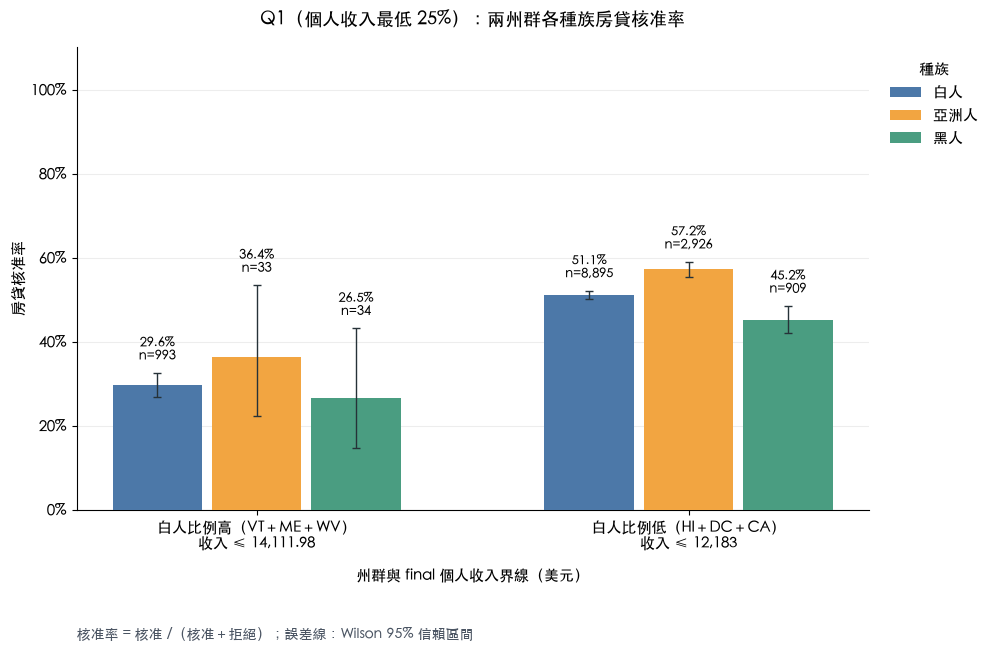

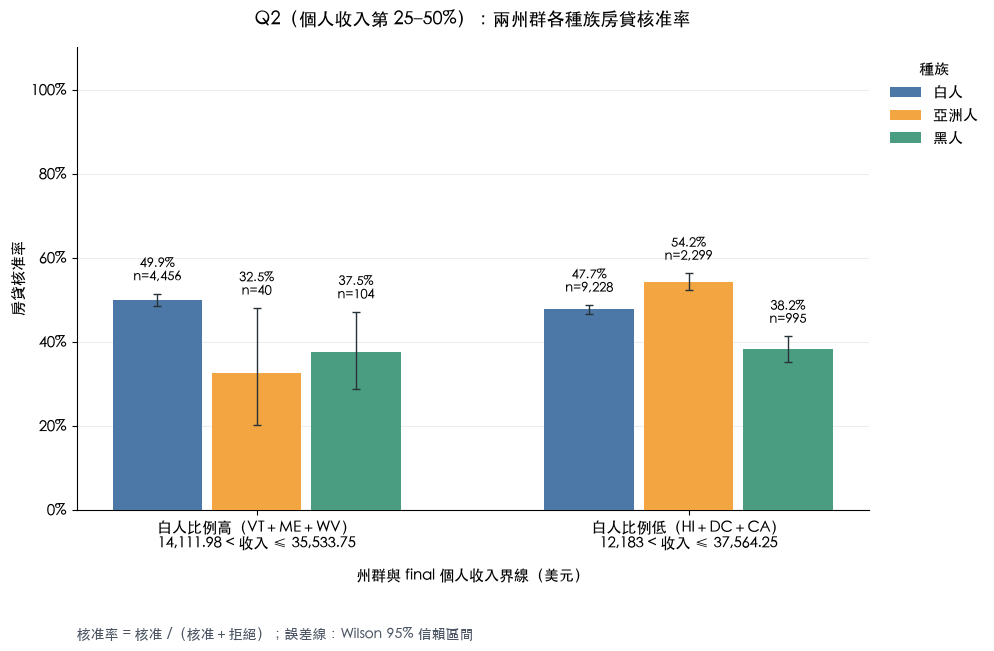

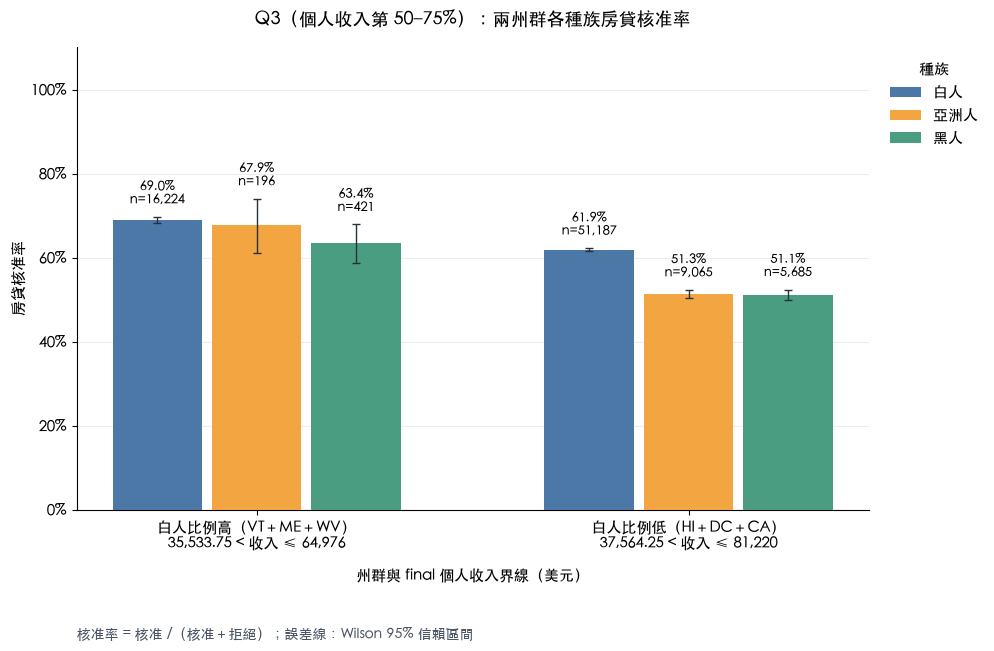

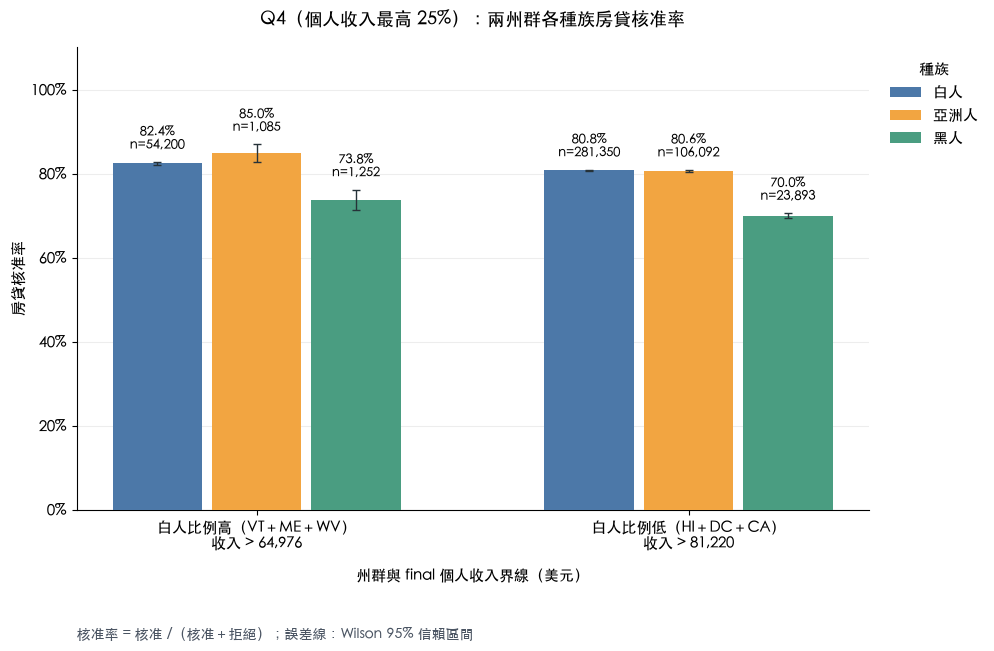

In [5]:
group_labels={groups[0]:'白人比例高（VT＋ME＋WV）',groups[1]:'白人比例低（HI＋DC＋CA）'}
colors=['#4C78A8','#F2A541','#4A9D81']
race_labels=['白人','亞洲人','黑人']
quartile_labels={'Q1':'個人收入最低 25%','Q2':'個人收入第 25–50%','Q3':'個人收入第 50–75%','Q4':'個人收入最高 25%'}
def income_range(state,q):
    a,b,c=[f'{v*1000:,.3f}'.rstrip('0').rstrip('.') for v in cutoffs.loc[state]]
    return {'Q1':f'收入 ≤ {a}', 'Q2':f'{a} < 收入 ≤ {b}', 'Q3':f'{b} < 收入 ≤ {c}', 'Q4':f'收入 > {c}'}[q]
def draw_chart(ax,q):
    width=.23
    for j,(race,label,color) in enumerate(zip(races,race_labels,colors)):
        group=summary.xs((q,race),level=('income_quartile','derived_race')).reindex(groups)
        x=np.arange(2)+(j-1)*width
        for k,row in enumerate(group.itertuples()):
            if row.n==0:
                ax.text(x[k],.025,'無樣本',ha='center',fontsize=9)
                continue
            ax.bar(x[k],row.approval_rate,width*.9,color=color,label=label if k==0 else None,zorder=3)
            ax.errorbar(x[k],row.approval_rate,yerr=[[max(0,row.approval_rate-row.ci95_low)],[max(0,row.ci95_high-row.approval_rate)]],fmt='none',ecolor='#263238',capsize=3,lw=1,zorder=4)
            ax.text(x[k],min(.99,row.ci95_high+.025),f'{row.approval_rate:.1%}\nn={row.n:,}',ha='center',va='bottom',fontsize=9)
    ax.set_title(f'{q}（{quartile_labels[q]}）：兩州群各種族房貸核准率',fontsize=13,pad=16)
    ax.set_xticks([0,1], [f'{group_labels[s]}\n{income_range(s,q)}' for s in groups])
    ax.set_xlabel('州群與 final 個人收入界線（美元）',labelpad=12)
    ax.set_ylabel('房貸核准率')
    ax.set_ylim(0,1.1)
    ax.set_yticks(np.arange(0,1.01,.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y',alpha=.22,zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(title='種族',loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
for q in ['Q1','Q2','Q3','Q4']:
    fig,ax=plt.subplots(figsize=(11,7))
    draw_chart(ax,q)
    fig.text(.1,.025,'核准率 = 核准 /（核准＋拒絕）；誤差線：Wilson 95% 信賴區間',fontsize=10,color='#4b5563')
    fig.subplots_adjust(left=.1,right=.82,bottom=.21,top=.87)
    fig.savefig(assets/f'{q}_approval_rate.png',dpi=180,facecolor='white')
    plt.show()
    plt.close(fig)
# A combined overview supports easy comparison; the four separate files are also saved.
fig,axes=plt.subplots(2,2,figsize=(19,13))
for ax,q in zip(axes.flat,['Q1','Q2','Q3','Q4']):
    draw_chart(ax,q)
fig.subplots_adjust(left=.06,right=.92,bottom=.13,top=.93,wspace=.44,hspace=.58)
fig.text(.06,.025,'門檻：[final]individual_income_quartiles_by_group.csv（final 州群個人收入）；核准 = action_taken 1、2；拒絕 = 3；誤差線：Wilson 95% 信賴區間',fontsize=10)
fig.savefig(assets/'all_quartiles.png',dpi=150,facecolor='white')
plt.close(fig)


本圖的州群構成不相同；低白人比例組的加州申請較多，因此合併比率主要反映該州的申請組成。兩群收入門檻不同，無法解讀為完全相同美元收入條件下的比較。房貸資料年份未確認，不能假定與 2024 ACS 同期。未控制信用、貸款條件、機構與州別差異；描述性差距不能解讀為歧視或因果效果。收入缺失排除亦可能影響組成。Wilson 區間未調整群聚相關性。作者待確認不影響數值計算，但交付前應補上實際作者。


In [6]:
for q in ['Q1','Q2','Q3','Q4']:
    lines=[]
    for race,label in zip(races,race_labels):
        high=summary.loc[(q,groups[0],race),'approval_rate']
        low=summary.loc[(q,groups[1],race),'approval_rate']
        lines.append(f'{label}：高白人比例組 {high:.1%}、低白人比例組 {low:.1%}（高−低 {(high-low)*100:+.1f} 個百分點）')
    display(Markdown(f'**{q}**：'+'；'.join(lines)+'。'))
print(f'執行完成：來源 {len(df):,} 筆；排除無效收入 {(~finite).sum():,} 筆；分析 {len(analysis):,} 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。')


**Q1**：白人：高白人比例組 29.6%、低白人比例組 51.1%（高−低 -21.5 個百分點）；亞洲人：高白人比例組 36.4%、低白人比例組 57.2%（高−低 -20.8 個百分點）；黑人：高白人比例組 26.5%、低白人比例組 45.2%（高−低 -18.7 個百分點）。

**Q2**：白人：高白人比例組 49.9%、低白人比例組 47.7%（高−低 +2.2 個百分點）；亞洲人：高白人比例組 32.5%、低白人比例組 54.2%（高−低 -21.7 個百分點）；黑人：高白人比例組 37.5%、低白人比例組 38.2%（高−低 -0.7 個百分點）。

**Q3**：白人：高白人比例組 69.0%、低白人比例組 61.9%（高−低 +7.1 個百分點）；亞洲人：高白人比例組 67.9%、低白人比例組 51.3%（高−低 +16.6 個百分點）；黑人：高白人比例組 63.4%、低白人比例組 51.1%（高−低 +12.3 個百分點）。

**Q4**：白人：高白人比例組 82.4%、低白人比例組 80.8%（高−低 +1.7 個百分點）；亞洲人：高白人比例組 85.0%、低白人比例組 80.6%（高−低 +4.3 個百分點）；黑人：高白人比例組 73.8%、低白人比例組 70.0%（高−低 +3.8 個百分點）。

執行完成：來源 606,291 筆；排除無效收入 24,729 筆；分析 581,562 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。
